# 04 — Main analysis: where should an adviser investigate first?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammed2008H/Reclaim-Front-End-/blob/main/notebooks/04_Zankalon_Screening.ipynb)

**Project RECLAIM · Precision Agriculture & Crop Intelligence · Zankalon, Sharqiya, Egypt**

### The product
A map and an evidence-backed **shortlist of locations to visit first** after a drop in vegetation greenness. Each flagged location comes with a reason and monthly charts, so an adviser can decide where to send a field team. **No AI model is trained;** the method is transparent rules on satellite indices.

### Reproduce the headline result (≈ 1 minute, CPU, no account)
Run all six numbered steps. At step 1 choose **one** of:
* `GITHUB_REPO_URL` filled in → the repository is cloned automatically (best for reviewers); or
* upload the supplied project ZIP; or
* upload `RECLAIM_Collection_For_04.zip` from notebook 03 if you also collected EnMAP pixels.

**Expected headline result:** 1,780 analysis cells → 1,519 eligible → **98 "review lower greenness"**, 1,307 "smaller net change", 114 "higher greenness", 261 excluded for limited reference cropland. Outputs appear under `results/` (open `START_HERE.html` for the interactive dashboard).

### Method in one paragraph
Sentinel-2 L2A reflectance (2023–2024, 10–20 m) is summarised into 100 m cells inside a WorldCover-2021 cropland reference. For each cell and calendar month we subtract 2023 from 2024 for four indices (NDVI, NDRE, NDMI, BSI), keep only well-observed months, and take the median NDVI change. A cell is flagged when that median is ≤ −0.05 with enough months and cropland pixels. These cutoffs are exploratory, not calibrated agronomic thresholds, and a sensitivity table shows how the shortlist changes.

### Read this before quoting numbers
Flags are **not** confirmed degraded farms: two years cannot establish long-term degradation, crop rotation/harvest timing/weather change the indices, and the 100 m cells can cross field boundaries. Step 5 adds EnMAP hyperspectral evidence **only if real pixels were supplied**; otherwise the dashboard says so.

## 1. Load the data package
Choose the ZIP downloaded from Notebook 03 to include any newly collected EnMAP data.
The loader checks the inputs and transfers the private clip into this notebook's runtime.


In [ ]:
#@title 1. Load your collection ZIP (or the supplied project ZIP)
UPLOAD_PROMPT='Choose RECLAIM_Collection_For_04.zip from Notebook 03, or the project ZIP for Sentinel-only results.'

from pathlib import Path
import io, json, zipfile, hashlib, importlib.util, sys, shutil
REQUIRED_HASHES = {'data/sample_input/zankalon_grid_monthly_pilot.csv': '5719dc384596df8b428977b13ce5763b1f65433794944d3770404aabd09bdf2b', 'data/sample_input/zankalon_analysis_grid.geojson': '7ee48a66b9087472b768859d3cf7531f4162c0d61d4d02401d67e153065cae45', 'data/sample_input/zankalon_collection_metadata_pilot.json': '887ad25b1a4a78a52e41f9c73809aa200f8c815ef028d850e0f232658431c75c', 'data/sample_input/zankalon_yearly_coverage.csv': '3ccc00da7ed5072c70344389078bf17bd573a8b0c1833a29410a5031587e274c', 'data/sample_input/zankalon_reference_crop_mask.tif': 'bcf0d62650c657e832dedeba9561115e8a6a10b67f120ca31a90c28ace967210', 'src/enmap_extension.py': '48cf4792899e745248c282892d5be8f06f41da6a3d3d36f7eef565ac31f0f165'}
INPUT_ZIP = ''  # Locally, optionally enter a ZIP path. In Colab leave this blank.
GITHUB_REPO_URL = ''  # After publishing, e.g. 'https://github.com/USER/REPO' -> Colab clones it, no ZIP upload.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None
if INPUT_ZIP:
    archive_source = INPUT_ZIP
elif GITHUB_REPO_URL:
    # No upload needed: fetch the public repository (this is the reviewer path).
    import subprocess
    clone_dir = Path.cwd()/'RECLAIM_Zankalon_Submission'
    if not clone_dir.exists():
        subprocess.run(['git','clone','--depth','1',GITHUB_REPO_URL,str(clone_dir)],check=True)
    archive_source = None
elif colab_files is not None:
    print(UPLOAD_PROMPT)
    uploaded = colab_files.upload()
    if len(uploaded) != 1:
        raise ValueError('Please select exactly one ZIP file.')
    archive_source = io.BytesIO(next(iter(uploaded.values())))
else:
    archive_source = None
roots = [Path.cwd(),Path.cwd().parent,Path.cwd()/'RECLAIM_Zankalon_Submission']
PROJECT_ROOT = next((p for p in roots if all((p/n).is_file() for n in REQUIRED_HASHES)), None)
if archive_source is not None:
    PROJECT_ROOT = PROJECT_ROOT or Path.cwd()/'RECLAIM_Zankalon_Submission'
    with zipfile.ZipFile(archive_source) as z:
        def find_member(name, required=True):
            hits=[x for x in z.namelist() if x==name or x.endswith('/'+name)]
            if len(hits)>1 or (required and not hits):
                raise ValueError('Missing or duplicate expected file: '+name)
            return hits[0] if hits else None
        for name, expected in REQUIRED_HASHES.items():
            member=find_member(name)
            if z.getinfo(member).file_size>20_000_000:raise ValueError('Unexpected file size.')
            content=z.read(member)
            if hashlib.sha256(content).hexdigest()!=expected:
                raise ValueError('Wrong package version or modified input: '+name)
            target=PROJECT_ROOT/name;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(content)
        # Optional private EnMAP input is imported only with a complete checksum manifest.
        manifest_name=find_member('data/hyperspectral/collection_status.json',required=False)
        hyper_dir=PROJECT_ROOT/'data/hyperspectral'
        if hyper_dir.exists() and any(hyper_dir.iterdir()):
            from datetime import datetime,timezone
            previous=PROJECT_ROOT/'work/previous_hyperspectral'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
            previous.parent.mkdir(parents=True,exist_ok=True);shutil.move(str(hyper_dir),str(previous))
        hyper_dir.mkdir(parents=True,exist_ok=True)
        if manifest_name:
            if z.getinfo(manifest_name).file_size>1_000_000:raise ValueError('Unexpected manifest size.')
            manifest=json.loads(z.read(manifest_name))
            manifest_files=manifest.get('files',{})
            allowed={'selected_item.json','enmap_clip_private.npz','coverage_candidates.csv','coverage_items.json'}
            if not set(manifest_files).issubset(allowed):raise ValueError('Unexpected collection file.')
            if manifest.get('state')=='pixels_ready_for_analysis' and not {'selected_item.json','enmap_clip_private.npz'}.issubset(manifest_files):
                raise ValueError('Collection says pixels ready but required files are missing.')
            for name,h in manifest_files.items():
                member=find_member('data/hyperspectral/'+name)
                if z.getinfo(member).file_size>80_000_000:raise ValueError('Unexpected hyperspectral clip size.')
                content=z.read(member)
                if hashlib.sha256(content).hexdigest()!=h:raise ValueError('Hyperspectral checksum mismatch: '+name)
                (hyper_dir/name).write_bytes(content)
            (hyper_dir/'collection_status.json').write_text(json.dumps(manifest,indent=2))
    if colab_files is not None and not INPUT_ZIP: del uploaded
if PROJECT_ROOT is None:
    raise FileNotFoundError('Extract the project ZIP and run from its root/notebooks folder, or open in Colab and upload the ZIP.')
for name,h in REQUIRED_HASHES.items():
    if hashlib.sha256((PROJECT_ROOT/name).read_bytes()).hexdigest()!=h:
        raise ValueError('Input or helper changed: '+name+'. Use the current package.')
spec=importlib.util.spec_from_file_location('reclaim_enmap',PROJECT_ROOT/'src/enmap_extension.py')
enmap=importlib.util.module_from_spec(spec);spec.loader.exec_module(enmap)
ROOT=PROJECT_ROOT
try:
    from IPython.display import display, Image, HTML
except ImportError:
    def display(value):print(value.to_string(index=False) if hasattr(value,'to_string') else value)
    Image=HTML=None
import base64, gzip, hashlib, io, json, zipfile, re, html
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle, Patch
try:
    from IPython.display import display, Image, HTML
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value,pd.DataFrame) else value)
    Image = HTML = None
np.random.seed(42)  # Analysis is deterministic; no random sampling is used.

INPUT_NAMES=['zankalon_grid_monthly_pilot.csv', 'zankalon_analysis_grid.geojson', 'zankalon_collection_metadata_pilot.json', 'zankalon_yearly_coverage.csv']
EXPECTED_HASHES={'zankalon_grid_monthly_pilot.csv': '5719dc384596df8b428977b13ce5763b1f65433794944d3770404aabd09bdf2b', 'zankalon_analysis_grid.geojson': '7ee48a66b9087472b768859d3cf7531f4162c0d61d4d02401d67e153065cae45', 'zankalon_collection_metadata_pilot.json': '887ad25b1a4a78a52e41f9c73809aa200f8c815ef028d850e0f232658431c75c', 'zankalon_yearly_coverage.csv': '3ccc00da7ed5072c70344389078bf17bd573a8b0c1833a29410a5031587e274c'}
packed={}
for name in INPUT_NAMES:
    content=(PROJECT_ROOT/'data/sample_input'/name).read_bytes()
    if hashlib.sha256(content).hexdigest()!=EXPECTED_HASHES[name]:
        raise ValueError('Input checksum mismatch: '+name+'. Use the supplied pilot inputs.')
    packed[name]=content.decode('utf-8')
OUT=PROJECT_ROOT/'results'
OUT.mkdir(exist_ok=True)
EXPORT_DETAIL_TABLES=True   # Save the matched-month pair table so every cell's result can be re-derived by hand (a few MB).
INDEXES=['NDVI','NDRE','NDMI','BSI']
raw=pd.read_csv(io.StringIO(packed['zankalon_grid_monthly_pilot.csv']))
geometry=json.loads(packed['zankalon_analysis_grid.geojson'])
source_metadata=json.loads(packed['zankalon_collection_metadata_pilot.json'])
if raw.duplicated(['cell_id','month']).any():raise ValueError('Duplicate cell/month rows.')
if set(raw.month.str[:4])!={'2023','2024'}:raise ValueError('This comparison expects 2023 and 2024.')
grid_ids=[f['properties']['cell_id'] for f in geometry['features']]
if len(grid_ids)!=len(set(grid_ids)) or set(grid_ids)!=set(raw.cell_id):
    raise ValueError('Grid geometry and input table do not match.')
print(f'Loaded {len(raw):,} rows for {raw.cell_id.nunique():,} analysis cells, 2023–2024.')
print('Source: Sentinel-2A/2B multispectral L2A; reference crop map: WorldCover 2021.')
print('2016–2025 was searched for availability only. No ML model is trained. Step 5 checks for actual EnMAP input.')
display(raw[['cell_id','month','NDVI','NDMI']].head())

Choose RECLAIM_Collection_For_04.zip from Notebook 03, or the project ZIP for Sentinel-only results.


Saving RECLAIM_Collection_For_04 (1).zip to RECLAIM_Collection_For_04 (1).zip
Loaded 42,720 rows for 1,780 analysis cells, 2023–2024.
Source: Sentinel-2A/2B multispectral L2A; reference crop map: WorldCover 2021.
2016–2025 was searched for availability only. No ML model is trained. Step 5 checks for actual EnMAP input.


,cell_id,month,NDVI,NDMI
0,R000_C000,2023-01,0.892556,0.415783
1,R000_C001,2023-01,0.868883,0.386067
2,R000_C002,2023-01,0.876371,0.454409
3,R000_C003,2023-01,0.859213,0.427397
4,R000_C004,2023-01,0.899143,0.414666


## 2. Keep measurements with enough coverage
The original values stay intact. We mark whether each cell/month can enter the comparison.

- All four indices must be present, with at least **80% of reference crop pixels** represented.
- The median observation count must be at least **2** for each index.
- A cell must contain at least **13 reference crop pixels** out of a nominal 25 pixels
  to receive a greenness category. This reduces mixed cropland/non-cropland cells.
- A cell needs at least **9 matched months** to receive that category.

These are transparent demo settings, not scientifically validated degradation thresholds.
Missing or excluded measurements are never replaced with zero or guessed values.


In [ ]:
#@title 2. Check measurement coverage
MIN_VALID_FRACTION = 0.80
MIN_OBSERVATIONS = 2
MIN_REFERENCE_PIXELS = 13
MIN_MATCHED_MONTHS = 9
CHANGE_THRESHOLD = 0.05  # NDVI index units, NOT a percentage
data = raw.copy()
data['year'] = data.month.str[:4].astype(int)
data['calendar_month'] = data.month.str[5:7].astype(int)
data['measurement_ok'] = data.processing_status.eq('complete')
for idx in INDEXES:
    data['measurement_ok'] &= (np.isfinite(data[idx]) &
        data[idx+'_valid_fraction'].ge(MIN_VALID_FRACTION) &
        data[idx+'_median_observations'].ge(MIN_OBSERVATIONS))
data['majority_reference_crop'] = data.reference_crop_pixels.ge(MIN_REFERENCE_PIXELS)
data['quality_reason'] = np.where(data.measurement_ok, 'Measurement retained',
    'Missing index or below coverage/observation rule')
quality = data.groupby('month').agg(total_cells=('cell_id','size'),
    cells_with_NDVI=('NDVI', lambda x: int(x.notna().sum())),
    cells_passing_measurement_rule=('measurement_ok','sum')).reset_index()
quality['retained_fraction'] = quality.cells_passing_measurement_rule/quality.total_cells
if EXPORT_DETAIL_TABLES:
    flag_cols = ['cell_id','year','calendar_month','processing_status','measurement_ok','majority_reference_crop','reference_crop_pixels'] + \
        [c for c in data.columns if any(c.startswith(i) for i in INDEXES)]
    data[[c for c in flag_cols if c in data.columns]].to_csv(OUT/'monthly_data_with_quality_flags.csv', index=False)
quality.to_csv(OUT/'monthly_coverage.csv', index=False)
print('Every original row stays in the input. Quality flags govern which comparisons are used.')
display(quality)


Every original row stays in the input. Quality flags govern which comparisons are used.


,month,total_cells,cells_with_NDVI,cells_passing_measurement_rule,retained_fraction
0,2023-01,1780,1780,1780,1.000000
1,2023-02,1780,1780,1780,1.000000
2,2023-03,1780,1371,1253,0.703933
3,2023-04,1780,1772,1713,0.962360
4,2023-05,1780,1780,1780,1.000000
5,2023-06,1780,1780,1780,1.000000
6,2023-07,1780,1780,1779,0.999438
7,2023-08,1780,1780,1780,1.000000
8,2023-09,1780,1778,1759,0.988202
9,2023-10,1780,1773,1765,0.991573


## 3. Compare like with like
For each grid cell, subtract its 2023 value from its 2024 value for the same month.
Use a month only when measurements pass in both years. Take the median of those
monthly differences. Median means the middle value when the differences are sorted.

**Example:** January 2023 NDVI = 0.70; January 2024 = 0.60; change = −0.10 index units.
This is not a 10% yield loss.

| Map label | Rule |
|---|---|
| Review lower greenness | Enough data/reference cropland, median NDVI change ≤ −0.05 |
| Smaller net change | Enough data/reference cropland, change between −0.05 and +0.05 |
| Higher greenness | Enough data/reference cropland, median change ≥ +0.05 |
| Insufficient comparison | Fewer than 9 matched months |
| Limited reference cropland | Fewer than 13 reference crop pixels |

A smaller net change can hide changes in individual months. Higher greenness does not
certify healthy land. The last two labels are data limitations, not land condition.


In [ ]:
#@title 3. Compare 2024 with 2023
paired = data[data.year.eq(2023)].merge(data[data.year.eq(2024)],
    on=['cell_id','calendar_month'], suffixes=('_2023','_2024'), validate='one_to_one')
paired['pair_ok'] = paired.measurement_ok_2023 & paired.measurement_ok_2024
for idx in INDEXES:
    paired['delta_'+idx] = (paired[idx+'_2024']-paired[idx+'_2023']).where(paired.pair_ok)
gb = paired.groupby('cell_id')
summary = gb.agg(matched_months=('pair_ok','sum'),
    reference_crop_pixels=('reference_crop_pixels_2023','first'))
for idx in INDEXES:
    summary['median_delta_'+idx] = gb['delta_'+idx].median()
summary['months_with_lower_NDVI'] = gb.delta_NDVI.agg(lambda s: int((s<0).sum()))
summary['eligible'] = (summary.matched_months.ge(MIN_MATCHED_MONTHS) &
    summary.reference_crop_pixels.ge(MIN_REFERENCE_PIXELS))
def classify(frame, threshold):
    status = pd.Series('Smaller net change', index=frame.index)
    status.loc[frame.median_delta_NDVI.le(-threshold)] = 'Review lower greenness'
    status.loc[frame.median_delta_NDVI.ge(threshold)] = 'Higher greenness'
    status.loc[frame.matched_months.lt(MIN_MATCHED_MONTHS)] = 'Insufficient comparison'
    status.loc[frame.reference_crop_pixels.lt(MIN_REFERENCE_PIXELS)] = 'Limited reference cropland'
    return status
summary['status'] = classify(summary, CHANGE_THRESHOLD)
reasons = []
for cid, r in summary.iterrows():
    if r.status == 'Limited reference cropland':
        reason = f'{int(r.reference_crop_pixels)}/25 nominal pixels are reference cropland; no land-condition category.'
    elif r.status == 'Insufficient comparison':
        reason = f'Only {int(r.matched_months)} matched months; at least {MIN_MATCHED_MONTHS} required.'
    else:
        reason = (f'Median matched-month NDVI change {r.median_delta_NDVI:+.3f}; '
            f'{int(r.months_with_lower_NDVI)}/{int(r.matched_months)} matched months have lower NDVI. '
            'Check crop type, timing and field conditions before interpreting the cause.')
    reasons.append(reason)
summary['reason'] = reasons
summary = summary.reset_index()
summary[['grid_row','grid_col']] = summary.cell_id.str.extract(r'R([0-9]+)_C([0-9]+)').astype(int)
summary['centre_easting_m'] = source_metadata['grid']['affine_first_six'][2]+summary.grid_col*100+50
summary['centre_northing_m'] = source_metadata['grid']['affine_first_six'][5]-summary.grid_row*100-50
summary['coordinate_epsg'] = source_metadata['epsg']
shortlist = summary[summary.status.eq('Review lower greenness')].sort_values(
    ['median_delta_NDVI','cell_id']).reset_index(drop=True)
sensitivity = pd.DataFrame([{'threshold_NDVI_units':t,
    'cells_flagged_for_review':int(classify(summary,t).eq('Review lower greenness').sum()),
    'eligible_cells':int(summary.eligible.sum())} for t in [0.03,0.05,0.08]])
if EXPORT_DETAIL_TABLES:
    pair_cols = ['cell_id','calendar_month','pair_ok','measurement_ok_2023','measurement_ok_2024'] + \
        [f'{i}_{y}' for i in INDEXES for y in (2023,2024)] + ['delta_'+i for i in INDEXES]
    paired[[c for c in pair_cols if c in paired.columns]].round(4).to_csv(OUT/'matched_month_comparisons.csv',index=False)
summary.to_csv(OUT/'cell_comparison_summary.csv',index=False)
shortlist.to_csv(OUT/'review_shortlist.csv',index=False)
sensitivity.to_csv(OUT/'threshold_sensitivity.csv',index=False)
print(f'{len(shortlist)} cells flagged for review out of {int(summary.eligible.sum())} eligible cells.')
print('Flags are exploratory. They are not confirmed degraded farms or independent training labels.')
display(summary.groupby('status').size().rename('cells').reset_index())
print('How the shortlist changes when the arbitrary threshold changes:')
display(sensitivity)

EXPECTED_COUNTS={'Smaller net change':1307,'Limited reference cropland':261,
                 'Higher greenness':114,'Review lower greenness':98}
actual_counts=summary.status.value_counts().to_dict()
if actual_counts!=EXPECTED_COUNTS:
    print('Result differs from the committed default; check whether you changed the settings.')
else:
    print('Default result reproduced: 98 review flags among 1,519 eligible cells.')


98 cells flagged for review out of 1519 eligible cells.
Flags are exploratory. They are not confirmed degraded farms or independent training labels.


,status,cells
0,Higher greenness,114
1,Limited reference cropland,261
2,Review lower greenness,98
3,Smaller net change,1307


How the shortlist changes when the arbitrary threshold changes:


,threshold_NDVI_units,cells_flagged_for_review,eligible_cells
0,0.03,213,1519
1,0.05,98,1519
2,0.08,30,1519


Default result reproduced: 98 review flags among 1,519 eligible cells.


## 4. View the map and a real example
The map shows **analysis cells**, which can cross several farms. It does not show ownership.
The highlighted cell is the largest measured decrease among the flagged cells; it is an
example selected for inspection, not a validated case of degradation.

In the downloaded results, open **START_HERE.html**. Click any cell to see its
explanation and its four monthly index comparisons. You can also choose its cell ID
from the list. The page works offline after download.


Created the offline interactive map, comparison tables and presentation figures.
Example cell: R040_C040; median NDVI difference -0.274. Cause unverified.


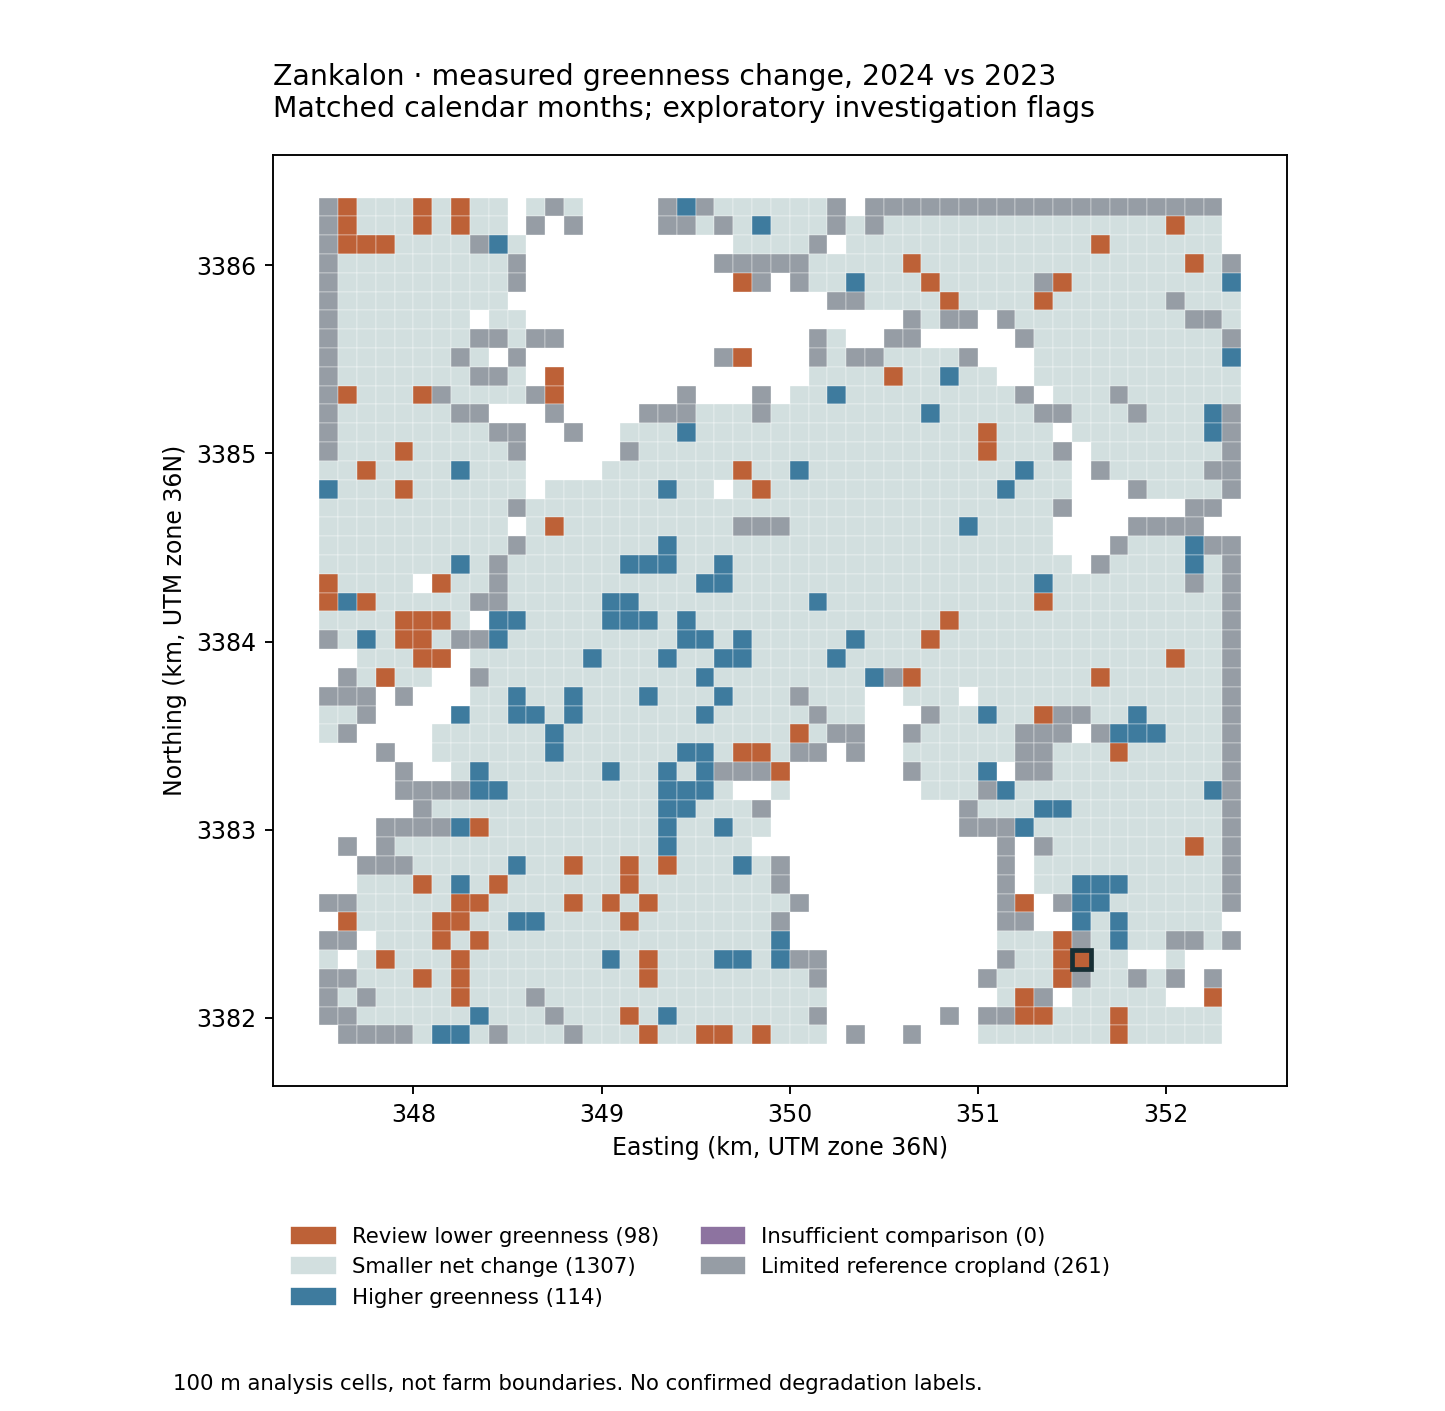

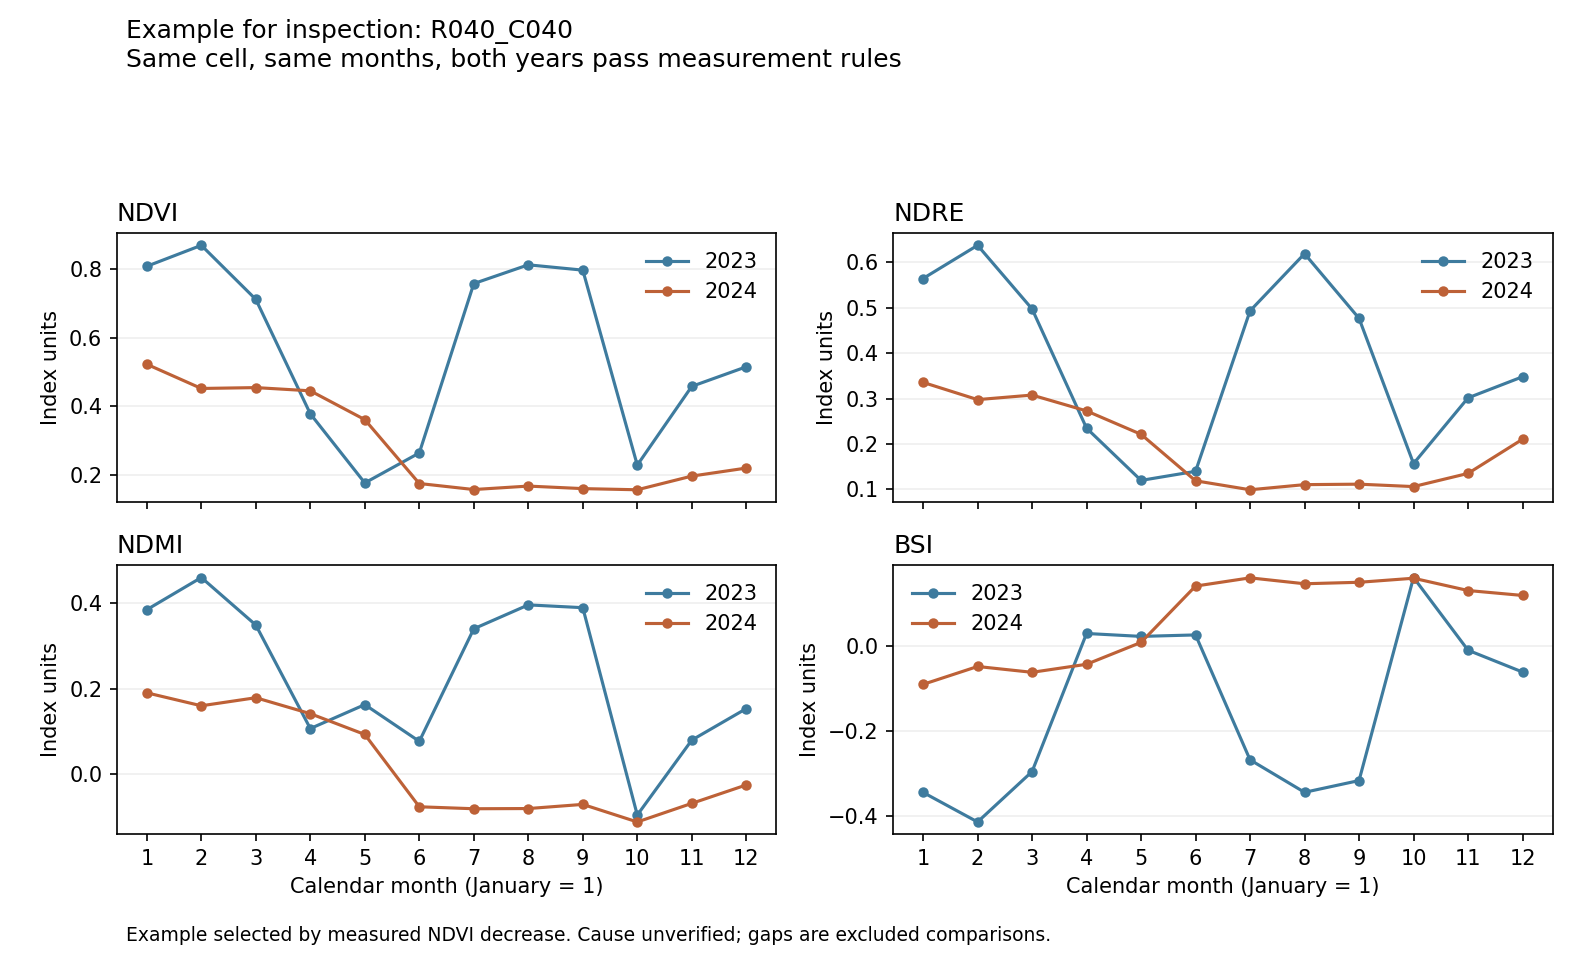

Results are saved in results/. Open START_HERE.html; Step 5 adds available EnMAP context; Step 6 saves the final ZIP.


In [ ]:
#@title 4. Make the map, charts and explanations
COLORS = {'Review lower greenness':'#bd6137', 'Smaller net change':'#d2dfdf',
    'Higher greenness':'#3e7b9e', 'Insufficient comparison':'#8d73a0',
    'Limited reference cropland':'#969da5'}
LABELS = list(COLORS)
summary_lookup = summary.set_index('cell_id')
example_id = (shortlist.iloc[0].cell_id if len(shortlist) else
    summary.sort_values(['matched_months','cell_id'],ascending=[False,True]).iloc[0].cell_id)

fig, ax = plt.subplots(figsize=(8.5,8.3))
patches = [Rectangle((r.centre_easting_m/1000-.05, r.centre_northing_m/1000-.05),.1,.1)
           for r in summary.itertuples()]
ax.add_collection(PatchCollection(patches, facecolor=[COLORS[s] for s in summary.status],
    edgecolor='white',linewidth=.15))
ax.autoscale_view(); ax.set_aspect('equal')
ex = summary_lookup.loc[example_id]
ax.add_patch(Rectangle((ex.centre_easting_m/1000-.05,ex.centre_northing_m/1000-.05),.1,.1,
    fill=False,edgecolor='#172f35',linewidth=2))
ax.set_xlabel('Easting (km, UTM zone 36N)'); ax.set_ylabel('Northing (km, UTM zone 36N)')
ax.ticklabel_format(useOffset=False)
ax.set_title('Zankalon · measured greenness change, 2024 vs 2023\n'
             'Matched calendar months; exploratory investigation flags',loc='left',pad=16)
handles = [Patch(color=COLORS[s],label=f'{s} ({int(summary.status.eq(s).sum())})') for s in LABELS]
ax.legend(handles=handles,loc='upper left',bbox_to_anchor=(0,-.13),ncol=2,frameon=False,fontsize=9)
fig.text(.12,.015,'100 m analysis cells, not farm boundaries. No confirmed degradation labels.',fontsize=9)
fig.subplots_adjust(bottom=.23,top=.89,left=.13,right=.95)
fig.savefig(OUT/'screening_map.png',dpi=170)
plt.close(fig)

fig, axes = plt.subplots(2,2,figsize=(10.5,6.4),sharex=True)
example_pairs = paired[paired.cell_id.eq(example_id)].sort_values('calendar_month')
for ax,idx in zip(axes.flat,INDEXES):
    for year,color in [(2023,'#3e7b9e'),(2024,'#bd6137')]:
        y=example_pairs[idx+'_'+str(year)].where(example_pairs.pair_ok)
        ax.plot(example_pairs.calendar_month,y,'o-',color=color,label=str(year),markersize=4)
    ax.set_title(idx,loc='left');ax.set_ylabel('Index units');ax.grid(axis='y',alpha=.2)
    ax.set_xticks(range(1,13));ax.legend(frameon=False)
for ax in axes[-1]:ax.set_xlabel('Calendar month (January = 1)')
fig.suptitle(f'Example for inspection: {example_id}\nSame cell, same months, both years pass measurement rules',x=.08,ha='left')
fig.tight_layout(rect=(0,.04,1,.9))
fig.text(.08,.02,'Example selected by measured NDVI decrease. Cause unverified; gaps are excluded comparisons.',fontsize=9)
fig.savefig(OUT/'example_comparison.png',dpi=150)
plt.close(fig)

properties = json.loads(summary.to_json(orient='records'))
property_lookup = {r['cell_id']:r for r in properties}
screen_geo = {'type':'FeatureCollection','features':[
    {'type':'Feature','geometry':f['geometry'],
     'properties':{**f['properties'],**property_lookup[f['properties']['cell_id']]}}
    for f in geometry['features']]}
(OUT/'screening_cells.geojson').write_text(json.dumps(screen_geo),encoding='utf-8')
rules = {'version':'1.0','base_year':2023,'comparison_year':2024,
    'minimum_valid_reference_crop_fraction':MIN_VALID_FRACTION,
    'minimum_median_observations':MIN_OBSERVATIONS,
    'minimum_reference_crop_pixels':MIN_REFERENCE_PIXELS,
    'nominal_pixels_per_cell':25,'minimum_matched_months':MIN_MATCHED_MONTHS,
    'ndvi_change_threshold_index_units':CHANGE_THRESHOLD,
    'statistic':'median of 2024 minus 2023 differences for accepted matched calendar months',
    'thresholds_validated':False,'model_trained':False,'independent_degradation_labels':False,
    'source_backup':'RECLAIM_Zankalon_Full_Backup.zip', 'input_sha256':EXPECTED_HASHES,
    'source_collection_metadata':source_metadata,
    'software':{'pandas':pd.__version__,'numpy':np.__version__},
    'counts':summary.status.value_counts().to_dict()}
(OUT/'method_and_provenance.json').write_text(json.dumps(rules,indent=2),encoding='utf-8')
data_payload = {'cells':properties,'colors':COLORS,'example':example_id,
    'threshold':CHANGE_THRESHOLD,'minmonths':MIN_MATCHED_MONTHS,
    'sensitivity':json.loads(sensitivity.to_json(orient='records')),'series':{},
    'coverage':json.loads(quality.to_json(orient='records'))}
for cid, group in paired.groupby('cell_id'):
    g=group.sort_values('calendar_month')
    data_payload['series'][cid]={'month':g.calendar_month.tolist(),'accepted':g.pair_ok.tolist()}
    for idx in INDEXES:
        for year in [2023,2024]:
            data_payload['series'][cid][idx+str(year)]=[
                round(float(v),5) if np.isfinite(v) else None for v in g[idx+'_'+str(year)]]
payload_text=json.dumps(data_payload,separators=(',',':'),allow_nan=False).replace('<','\\u003c')
page = r'''<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>RECLAIM · Zankalon investigation map</title>
<style>
*{box-sizing:border-box}body{margin:0;background:#f4f6f4;color:#193539;font:15px/1.5 system-ui,sans-serif}
main{max-width:1220px;margin:auto;padding:30px}h1{font-size:30px;font-weight:600;margin:0 0 8px}h2{font-size:20px;margin:0 0 10px}h3{font-size:16px;margin:0}
p{margin:7px 0 14px}.muted{color:#53686a}.eyebrow{font-size:12px;letter-spacing:2px;margin-bottom:8px}
.summary{display:flex;flex-wrap:wrap;gap:28px;border-top:1px solid #d4dddd;border-bottom:1px solid #d4dddd;padding:16px 0;margin:20px 0}.summary b{font-size:25px;display:block}
.layout{display:grid;grid-template-columns:minmax(0,1.15fr) minmax(0,1fr);gap:26px}.panel{background:white;padding:20px;border-radius:10px}
svg{display:block;width:100%;height:auto}#map rect.cell{cursor:pointer}#map rect.selected{stroke:#162f35;stroke-width:2}
.legend{display:flex;flex-wrap:wrap;gap:8px 16px;font-size:12px;margin:8px 0}.swatch{display:inline-block;width:11px;height:11px;margin-right:5px}
label{display:block;margin:5px 0}select{font:inherit;width:100%;padding:8px;border:1px solid #b4c4c5;background:white;color:#193539;border-radius:5px}
.status{font-size:16px;font-weight:600;margin-top:14px}.numbers{display:grid;grid-template-columns:1fr 1fr;gap:8px;margin:15px 0}.numbers b{font-size:22px;display:block}.numbers span{font-size:12px;color:#53686a}
.charts{display:grid;grid-template-columns:1fr 1fr;gap:12px}.chart text{font:12px system-ui;fill:#425c60}.chart h3{margin-top:4px}
table{border-collapse:collapse;width:100%;font-size:13px}th,td{text-align:left;border-bottom:1px solid #e0e6e5;padding:8px 6px}details{margin-top:22px}summary{cursor:pointer;font-size:17px;font-weight:600}
.notice{border-left:3px solid #bd6137;padding-left:12px}.after{margin-top:24px}a{color:#2d647e}button{padding:8px 12px;font:inherit;cursor:pointer;background:#193539;color:white;border:0;border-radius:5px}
@media(max-width:850px){main{padding:18px}.layout{grid-template-columns:1fr}.panel{padding:16px}}
@media(max-width:450px){.charts{grid-template-columns:1fr}h1{font-size:25px}.summary{gap:16px}.summary b{font-size:22px}}
@media print{details{display:block}.layout{display:block}.panel{break-inside:avoid}button,select{display:none}}
</style></head><body><main>
<div class="eyebrow">RECLAIM / EGYPT / ZANKALON PILOT</div>
<h1>Which areas deserve a closer look?</h1>
<p class="muted">Compare satellite-measured greenness in 2024 with the same months in 2023.</p>
<p class="notice">Exploratory screening. Orange cells have lower measured greenness under the stated rules.
The cause is unverified. This is not a trained degradation model.</p>
<div class="summary" id="totals"></div>
<div class="layout"><section class="panel"><h2>Investigation map</h2>
<p class="muted">Click a grid cell. Each square represents a nominal 100 m analysis cell.</p>
<svg id="map" viewBox="0 0 560 550" role="img" aria-label="Zankalon comparison grid. Use the cell selector for keyboard access."></svg>
<div id="legend" class="legend"></div>
<p class="muted">Grid positions use the original UTM coordinates. Farm boundaries, ownership and roads are not included.</p>
</section><section class="panel"><h2>Inspect one location</h2><label for="pick">Cell ID</label><select id="pick"></select>
<div id="detail" aria-live="polite"></div>
<div class="legend"><span><i class="swatch" style="background:#3e7b9e"></i>2023</span><span><i class="swatch" style="background:#bd6137"></i>2024</span></div>
<div id="charts" class="charts"></div>
<p class="muted">Index units, not yield percentages. Only months passing the measurement rules in both years are plotted. A break in the line is an excluded comparison.</p>
</section></div>
<section class="panel after"><h2>What to do with a flagged cell</h2>
<ol><li>Check its graph and how many months support the comparison.</li>
<li>Check whether the crop, planting date, harvest date or irrigation changed between years.</li>
<li>Ask an agronomist or field operator to verify the site and record actual crop, yield and soil observations.</li></ol>
<p>Use the shortlist to plan investigation. It does not establish rehabilitation cost, recoverability or investment returns.</p>
<details><summary>How the comparison works</summary>
<p>Each month has median satellite index values. A measurement is accepted only when all four indices are present,
at least 80% of the reference crop pixels are represented for each index, the median observation count is at least 2,
and processing completed. Accepted measurements are matched by cell and calendar month across the two years.</p>
<p>A greenness category requires at least 9 matched months and at least 13 reference crop pixels out of a nominal 25.
We calculate the median of the monthly differences (2024 minus 2023). A value at or below −0.05 triggers a review flag;
at or above +0.05 is higher greenness. Intermediate values are smaller net change. These demo cutoffs are not calibrated
against field outcomes. Changing them changes the result.</p>
<div id="sensitivity"></div>
<p>Same-month comparison reduces seasonal mismatch but does not control for crop rotation, planting shifts,
weather, pests or land-use changes. The crop reference is ESA WorldCover 2021, not a crop map for each comparison year.
Monthly values may use different clear pixels within the same cell. Cells with few reference crop pixels are excluded
from greenness categories. No interpolation, supervised training, accuracy assessment or ten-year trend is performed.</p>
</details>
<details><summary>Data coverage by month</summary><div id="coverage"></div></details>
<details><summary>Sources and files</summary>
<p>Input: your RECLAIM_Zankalon_Full_Backup.zip, collected 3 October 2026. The 42,720 monthly rows cover 1,780 cells
and 24 months in 2023–2024. The earlier 2016–2025 audit searched catalogue availability only.</p>
<p>Satellite source: <a href="https://earth-search.aws.element84.com/v1">Element 84 Earth Search</a>, Sentinel-2 L2A.
Reference cropland: <a href="https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200">ESA WorldCover 2021 v200</a>, class 40.
Contains modified Copernicus Sentinel data. © ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium.</p>
<p>review_shortlist.csv lists investigation candidates. cell_comparison_summary.csv lists all cells.
matched_month_comparisons.csv holds every 2023-vs-2024 month pair per cell (the numbers behind each median), and monthly_data_with_quality_flags.csv shows which monthly measurements passed the quality rules. method_and_provenance.json records settings and input hashes.
screening_cells.geojson allows GIS reuse. The two PNG files are static presentation figures.</p>
</details></section>
<noscript><p>Enable JavaScript for cell selection, or open screening_map.png and review_shortlist.csv.</p></noscript>
</main><script id="reclaim-data" type="application/json">__DATA__</script>
<script>
'use strict';
const D=JSON.parse(document.getElementById('reclaim-data').textContent), byId=new Map(D.cells.map(c=>[c.cell_id,c]));
const NS='http://www.w3.org/2000/svg';
const el=(name,attrs={},text='')=>{const a=document.createElementNS(NS,name);for(const [k,v] of Object.entries(attrs))a.setAttribute(k,String(v));if(text)a.textContent=text;return a;};
const fmt=v=>v===null?'Unavailable':(v>=0?'+':'')+v.toFixed(3);
const eligible=D.cells.filter(c=>c.eligible), flagged=D.cells.filter(c=>c.status==='Review lower greenness');
document.getElementById('totals').innerHTML=`<div><b>${D.cells.length.toLocaleString()}</b>analysis cells</div><div><b>${eligible.length.toLocaleString()}</b>eligible for comparison</div><div><b>${flagged.length.toLocaleString()}</b>flagged for investigation</div>`;
const map=document.getElementById('map'), maxr=Math.max(...D.cells.map(c=>c.grid_row))+1,maxc=Math.max(...D.cells.map(c=>c.grid_col))+1;
const scale=Math.min(475/maxc,450/maxr),ox=47,oy=30;
for(const c of D.cells){const rect=el('rect',{x:ox+c.grid_col*scale,y:oy+c.grid_row*scale,width:scale-.25,height:scale-.25,fill:D.colors[c.status],class:'cell','data-id':c.cell_id});rect.appendChild(el('title',{},c.cell_id+': '+c.status));rect.addEventListener('click',()=>selectCell(c.cell_id));map.appendChild(rect);}
map.appendChild(el('text',{x:ox+maxc*scale-10,y:18,'font-size':13,'text-anchor':'end'},'N ↑'));
map.appendChild(el('text',{x:ox,y:oy+maxr*scale+24,'font-size':13},'West → East · 1 cell = 100 m'));
map.appendChild(el('line',{x1:ox,y1:oy+maxr*scale+40,x2:ox+5*scale,y2:oy+maxr*scale+40,stroke:'#193539','stroke-width':2}));
map.appendChild(el('text',{x:ox+5*scale+8,y:oy+maxr*scale+44,'font-size':12},'500 m'));
document.getElementById('legend').innerHTML=Object.entries(D.colors).map(([s,c])=>`<span><i class="swatch" style="background:${c}"></i>${s}</span>`).join('');
const pick=document.getElementById('pick');
for(const c of D.cells){const o=document.createElement('option');o.value=c.cell_id;o.textContent=c.cell_id+' · '+c.status;pick.appendChild(o);}pick.addEventListener('change',()=>selectCell(pick.value));
function chart(idx,s){
 const wrap=document.createElement('div');wrap.className='chart';const title=document.createElement('h3');title.textContent=idx;wrap.appendChild(title);
 const svg=el('svg',{viewBox:'0 0 280 190',role:'img','aria-label':idx+' monthly values for 2023 and 2024'});wrap.appendChild(svg);
 const vals=[...s[idx+'2023'],...s[idx+'2024']].filter(v=>v!==null);let lo=Math.min(...vals),hi=Math.max(...vals);const pad=Math.max((hi-lo)*.12,.03);lo-=pad;hi+=pad;
 const X=m=>43+(m-1)*20,Y=v=>147-(v-lo)/(hi-lo)*119;
 for(let i=0;i<3;i++){const v=lo+(hi-lo)*i/2,y=Y(v);svg.appendChild(el('line',{x1:43,x2:263,y1:y,y2:y,stroke:'#dbe3e3'}));svg.appendChild(el('text',{x:37,y:y+4,'text-anchor':'end'},v.toFixed(2)));}
 for(const m of [1,4,7,10,12])svg.appendChild(el('text',{x:X(m),y:164,'text-anchor':'middle'},String(m)));
 svg.appendChild(el('text',{x:153,y:184,'text-anchor':'middle'},'Calendar month'));
 for(const [year,color] of [[2023,'#3e7b9e'],[2024,'#bd6137']]){
  let path='',active=false;const ys=s[idx+year];
  for(let i=0;i<s.month.length;i++){const v=ys[i];if(!s.accepted[i]||v===null){active=false;continue;}path+=(active?'L':'M')+X(s.month[i])+','+Y(v)+' ';active=true;const dot=el('circle',{cx:X(s.month[i]),cy:Y(v),r:2.8,fill:color});dot.appendChild(el('title',{},year+' month '+s.month[i]+': '+v.toFixed(3)));svg.appendChild(dot);}
  svg.appendChild(el('path',{d:path,fill:'none',stroke:color,'stroke-width':1.8}));
 }return wrap;
}
function selectCell(id){
 const c=byId.get(id);pick.value=id;document.querySelectorAll('#map .selected').forEach(e=>e.classList.remove('selected'));document.querySelector(`#map [data-id="${id}"]`).classList.add('selected');
 const detail=document.getElementById('detail');detail.innerHTML=`<div class="status">${c.status}</div><div class="numbers"><div><b>${fmt(c.median_delta_NDVI)}</b><span>median NDVI change (index units)</span></div><div><b>${c.matched_months}/12</b><span>months passing in both years</span></div></div>`;
 const p=document.createElement('p');p.textContent=c.reason;detail.appendChild(p);
 const coords=document.createElement('p');coords.className='muted';coords.textContent=`UTM 36N centre: ${c.centre_easting_m.toFixed(0)} E, ${c.centre_northing_m.toFixed(0)} N (metres).`;detail.appendChild(coords);
 const holder=document.getElementById('charts');holder.replaceChildren();for(const idx of ['NDVI','NDRE','NDMI','BSI'])holder.appendChild(chart(idx,D.series[id]));
}
document.getElementById('sensitivity').innerHTML='<table><thead><tr><th>NDVI threshold</th><th>Review flags</th><th>Eligible cells</th></tr></thead><tbody>'+D.sensitivity.map(r=>`<tr><td>±${r.threshold_NDVI_units.toFixed(2)}</td><td>${r.cells_flagged_for_review}</td><td>${r.eligible_cells}</td></tr>`).join('')+'</tbody></table>';
document.getElementById('coverage').innerHTML='<table><thead><tr><th>Month</th><th>Cells passing measurement rule</th><th>Share of all cells</th></tr></thead><tbody>'+D.coverage.map(r=>`<tr><td>${r.month}</td><td>${r.cells_passing_measurement_rule} / ${r.total_cells}</td><td>${(r.retained_fraction*100).toFixed(1)}%</td></tr>`).join('')+'</tbody></table>';
selectCell(D.example);
</script></body></html>'''
(OUT/'START_HERE.html').write_text(page.replace('__DATA__',payload_text),encoding='utf-8')
(OUT/'READ_ME.txt').write_text('''RECLAIM ZANKALON SCREENING RESULTS

1. Open START_HERE.html in Chrome or Edge. The page works offline.
2. Click a cell, or choose its ID. Inspect its reason and monthly curves.
3. Use review_shortlist.csv as an investigation list, not as verified degradation labels.
4. Keep your original collection backup and the executed 04 notebook.

All results use your actual 2023-2024 summary data. Thresholds are exploratory.
No machine learning model was trained. No accuracy percentage was measured.
Same-month comparison does not resolve crop rotation, timing or weather differences.
The cropland mask is a static 2021 reference. The grid does not represent farms or ownership.
Two years do not establish persistent land degradation or a ten-year trend.
No yield loss, rehabilitation cost or financial return has been estimated.

For a demonstration: show a flagged location, its graph, the data-quality rules and
the field questions needed to verify the cause. Present the business benefit as
prioritizing inspection effort, with savings still to be measured in a customer pilot.

For a stronger implementation, validate flagged locations with field observations and
crop information. This project is an analysis and decision-support workflow; no model
training is required to produce its current output.

The project includes the source table and geometry in data/sample_input for reproduction.
method_and_provenance.json records the rules, sources and file checksums.
''',encoding='utf-8')
print('Created the offline interactive map, comparison tables and presentation figures.')
print(f'Example cell: {example_id}; median NDVI difference {ex.median_delta_NDVI:+.3f}. Cause unverified.')
if Image is not None:
    display(Image(filename=str(OUT/'screening_map.png')))
    display(Image(filename=str(OUT/'example_comparison.png')))
print('Results are saved in results/. Open START_HERE.html; Step 5 adds available EnMAP context; Step 6 saves the final ZIP.')


## 5. Add hyperspectral evidence to the same dashboard
This runs automatically if the package contains a genuine EnMAP clip collected by 03.
It examines the detailed vegetation spectrum, adds a dated graph and links measurements
to the same cell IDs. It does not change the original Sentinel investigation categories.

If Colab reports that rasterio is missing, run `%pip install rasterio==1.4.4` in a new
code cell, then rerun this step. EnMAP pixels are needed; installing software does not
create data. When no pixels are supplied, a clear pending-data message is added instead.

**How to interpret it:** red-edge shape is descriptive evidence on the acquisition date.
Crop type, season and management can explain differences. It is not a measured salinity,
chlorophyll concentration, accuracy score or proof of long-term degradation.


In [ ]:
#@title 5. Analyse available EnMAP pixels and update the dashboard
HYPER_OUT=OUT/'hyperspectral'
if HYPER_OUT.exists() and any(HYPER_OUT.iterdir()):
    from datetime import datetime,timezone
    previous=PROJECT_ROOT/'work/previous_enmap_results'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    previous.parent.mkdir(parents=True,exist_ok=True);shutil.move(str(HYPER_OUT),str(previous))
HYPER_OUT.mkdir(parents=True,exist_ok=True)
hyper_input=PROJECT_ROOT/'data/hyperspectral'
manifest_file=hyper_input/'collection_status.json'
manifest=json.loads(manifest_file.read_text()) if manifest_file.exists() else {'state':'not_collected'}
details=enmap.status(HYPER_OUT,'not_available',collection_state=manifest.get('state'),
                     explanation='Sentinel-only result: no completed hyperspectral input supplied.')
if manifest.get('state')=='pixels_ready_for_analysis':
    try:
        if not {'selected_item.json','enmap_clip_private.npz'}.issubset(manifest.get('files',{})):
            raise ValueError('The collection manifest is missing the required pixel/scene checksums.')
        for name,h in manifest.get('files',{}).items():
            if name not in {'selected_item.json','enmap_clip_private.npz','coverage_candidates.csv','coverage_items.json'}:
                raise ValueError('Unexpected collection file.')
            if hashlib.sha256((hyper_input/name).read_bytes()).hexdigest()!=h:
                raise ValueError('Hyperspectral input checksum mismatch: '+name)
        import rasterio
        item=json.loads((hyper_input/'selected_item.json').read_text())
        if item.get('collection') != enmap.COLLECTION:raise ValueError('Expected EnMAP L2A scene metadata.')
        table,details=enmap.analyse_clip(PROJECT_ROOT,item,hyper_input/'enmap_clip_private.npz')
        for name in ['selected_item.json','coverage_candidates.csv','coverage_items.json']:
            if (hyper_input/name).is_file():shutil.copy2(hyper_input/name,HYPER_OUT/name)
        display(table.head(10))
        if Image is not None:display(Image(filename=str(HYPER_OUT/'enmap_red_edge_spectra.png')))
        print('Actual EnMAP observation date:',details['acquisition_utc'])
        print('Cells with usable spectra:',details['cells_with_spectra'])
        print(details['temporal_relationship'])
    except Exception as exc:
        # Move partial products out of the final public result if processing failed.
        for p in list(HYPER_OUT.iterdir()):
            if p.is_file() and p.name!='hyperspectral_status.json':
                target=PROJECT_ROOT/'work/failed_enmap_outputs'/p.name
                target.parent.mkdir(parents=True,exist_ok=True);shutil.move(str(p),str(target))
        details=enmap.status(HYPER_OUT,'analysis_failed',error_type=type(exc).__name__)
        print('EnMAP analysis did not complete:',str(exc))
        print('If rasterio is missing, install rasterio==1.4.4 and rerun this step.')
else:
    print('No completed EnMAP clip supplied. This run uses Sentinel-2 for 2023–2024.')
enmap.attach_to_dashboard(PROJECT_ROOT,details)
print('Dashboard updated. Hyperspectral state:',details['state'])
print('Open results/START_HERE.html after downloading Step 6.')


No completed EnMAP clip supplied. This run uses Sentinel-2 for 2023–2024.
Dashboard updated. Hyperspectral state: not_available
Open results/START_HERE.html after downloading Step 6.


## 6. Download the final results
Download **RECLAIM_Final_Results.zip**, unzip it and open **START_HERE.html** in your
browser. This is the final dashboard. If EnMAP analysis succeeded, its graph and cell
evidence are included. Otherwise the dashboard clearly says hyperspectral data was not
analysed. Download the executed notebook too using File → Download → Download .ipynb.

This result ZIP includes derived evidence, not private pixel cubes or credentials.
Copy its contents into the project's `results/` folder before submitting the repository.
Do not present the optional EnMAP feature as a completed result unless its status is
`analysis_complete` and a real dated spectral output is present.


In [ ]:
#@title 6. Save the final dashboard and results
download_dir=PROJECT_ROOT/'downloads'
download_dir.mkdir(exist_ok=True)
archive_path=download_dir/'RECLAIM_Final_Results.zip'
with zipfile.ZipFile(archive_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file() and p.suffix not in {'.npz','.tif','.tiff'}:
            z.write(p,p.relative_to(OUT))
print('Final results:',archive_path.name)
print('Sentinel-2 baseline: 2023–2024. EnMAP status:',details['state'])
print('Unzip the download and open START_HERE.html.')
if colab_files is not None:colab_files.download(str(archive_path))


Final results: RECLAIM_Final_Results.zip
Sentinel-2 baseline: 2023–2024. EnMAP status: not_available
Unzip the download and open START_HERE.html.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**What to submit:** the two executed notebooks, root README, pinned requirements,
small Sentinel sample inputs, actual derived results, team details and presentation
PDF, plus the platform form and accessible GitHub link specified in the screenshots.

The business decision is where to investigate first. Savings and profitability have
not been measured; the 98 flags are not verified damaged farms. The 100 m squares
can cross farm boundaries. Two years do not establish a long-term degradation trend.

EnMAP source/access: https://www.enmap.org/data_access/ . Respect the provider licence;
private raw/clipped pixel data are excluded from public outputs. Exact EnMAP scene,
date and attribution are recorded after successful analysis. Sentinel and WorldCover
attributions are in the root README. No unrelated Tanager tutorial image is used.
